# EDA profundo: demanda de bicicletas en Seúl
**Objetivo:** comprender la demanda horaria (`Rented Bike Count`), detectar problemas de calidad y establecer precauciones antes de construir un modelo predictivo de regresión o pronóstico.

**Dataset:** `data/SeoulBikeData.csv`. Una observación por hora; no hay identificación de usuarios ni estaciones. Este análisis conserva los datos originales: las columnas derivadas solo se crean en memoria. No se entrena ningún modelo.

| Columna normalizada | Columna original / significado |
|---|---|
| `fecha`, `hora` | Date (día/mes/año), Hour (0–23) |
| **`alquileres`** | **Rented Bike Count: conteo objetivo por hora** |
| `temperatura_c` | Temperatura en °C |
| `humedad_pct` | Humedad relativa (%) |
| `viento_ms` | Velocidad del viento (m/s) |
| `visibilidad_10m` | Visibilidad en unidades de 10 metros |
| `rocio_c` | Temperatura del punto de rocío (°C) |
| `radiacion_mj_m2` | Radiación solar (MJ/m²) |
| `lluvia_mm` | Precipitación (mm) |

**Índice**
1. Carga y calidad de los datos
2. Variable objetivo
3. Variables numéricas y valores extremos
4. Calendario y demanda
5. Asociaciones con el objetivo
6. Segmentos y cruces
7. Correlaciones y dependencia temporal
8. Anomalías, relaciones estructurales y fuga de información
9. Información mutua exploratoria
10. Hallazgos y próximos pasos

## 0. Configuración

Requiere pandas, numpy, matplotlib, scikit-learn e IPython; para ejecutar desde Jupyter se necesita un kernel Python con estas bibliotecas.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_selection import mutual_info_regression

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA = "#4C72B0", "#DD8452"
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| numpy:", np.__version__)

Python: 3.14.0 | pandas: 2.3.3 | numpy: 2.3.5


## 1. Carga y calidad de los datos

In [2]:
# Funciona al abrir el kernel desde notebook/ o desde la raíz del repositorio.
candidatas = [Path.cwd(), *Path.cwd().parents]
RAIZ = next((p for p in candidatas if (p / "data/SeoulBikeData.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("No se encuentra data/SeoulBikeData.csv desde el directorio del kernel")
RUTA = RAIZ / "data/SeoulBikeData.csv"
original = pd.read_csv(RUTA, encoding="utf-8")

# Se identifican los nombres de temperatura sin depender del símbolo dañado.
def nombre_normalizado(c):
    nombres = {"Date": "fecha", "Rented Bike Count": "alquileres", "Hour": "hora",
               "Humidity(%)": "humedad_pct", "Wind speed (m/s)": "viento_ms",
               "Visibility (10m)": "visibilidad_10m", "Solar Radiation (MJ/m2)": "radiacion_mj_m2",
               "Rainfall(mm)": "lluvia_mm"}
    if c.startswith("Temperature("): return "temperatura_c"
    if c.startswith("Dew point temperature("): return "rocio_c"
    return nombres.get(c, c)

renombrado = {c: nombre_normalizado(c) for c in original.columns}
display(pd.DataFrame(renombrado.items(), columns=["original", "normalizada"]))
df = original.rename(columns=renombrado).copy()
TARGET = "alquileres"
CLIMA = ["temperatura_c", "humedad_pct", "viento_ms", "visibilidad_10m",
         "rocio_c", "radiacion_mj_m2", "lluvia_mm"]
assert set(df.columns) == {"fecha", "hora", TARGET, *CLIMA}, "Esquema inesperado"
print(f"Filas: {len(df):,} | Columnas originales: {original.shape[1]}")
display(df.head())

,original,normalizada
0,Date,fecha
1,Rented Bike Count,alquileres
2,Hour,hora
3,Temperature(�C),temperatura_c
4,Humidity(%),humedad_pct
5,Wind speed (m/s),viento_ms
6,Visibility (10m),visibilidad_10m
7,Dew point temperature(�C),rocio_c
8,Solar Radiation (MJ/m2),radiacion_mj_m2
9,Rainfall(mm),lluvia_mm


Filas: 8,760 | Columnas originales: 10


,fecha,alquileres,hora,temperatura_c,humedad_pct,viento_ms,visibilidad_10m,rocio_c,radiacion_mj_m2,lluvia_mm
0,01/12/2017,254,0,-5.200,37,2.200,2000,-17.600,0.000,0.000
1,01/12/2017,204,1,-5.500,38,0.800,2000,-17.600,0.000,0.000
2,01/12/2017,173,2,-6.000,39,1.000,2000,-17.700,0.000,0.000
3,01/12/2017,107,3,-6.200,40,0.900,2000,-17.600,0.000,0.000
4,01/12/2017,78,4,-6.000,36,2.300,2000,-18.600,0.000,0.000


In [3]:
calidad = pd.DataFrame({"tipo": original.dtypes.astype(str), "nulos": original.isna().sum(),
                        "valores_unicos": original.nunique(), "ejemplo": original.iloc[0]})
display(calidad)
print("Duplicados completos:", original.duplicated().sum())
print("Valores numéricos finitos:", np.isfinite(df[[TARGET, "hora"] + CLIMA]).all().all())
print("Encabezados con carácter de reemplazo:", [c for c in original if "\ufffd" in c])
# El símbolo de reemplazo está en el CSV; otra codificación no recupera el carácter perdido.
df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y", errors="raise")
assert df["hora"].between(0, 23).all() and df["hora"].mod(1).eq(0).all()
df["timestamp"] = df["fecha"] + pd.to_timedelta(df["hora"], unit="h")
print("Orden cronológico original:", df["timestamp"].is_monotonic_increasing)
print("Timestamps duplicados:", df["timestamp"].duplicated().sum())
df = df.sort_values("timestamp").reset_index(drop=True)
assert not df["timestamp"].duplicated().any(), "Resolver timestamps duplicados antes del análisis temporal"
esperadas = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq="h")
faltantes = esperadas.difference(pd.DatetimeIndex(df.timestamp))
print("Periodo:", df.timestamp.min(), "a", df.timestamp.max())
print("Horas faltantes:", len(faltantes))
display(df.groupby("fecha").size().value_counts().rename_axis("horas_por_dia").to_frame("dias"))

,tipo,nulos,valores_unicos,ejemplo
Date,object,0,365,01/12/2017
Rented Bike Count,int64,0,2166,254
Hour,int64,0,24,0
Temperature(�C),float64,0,546,-5.200
Humidity(%),int64,0,90,37
Wind speed (m/s),float64,0,65,2.200
Visibility (10m),int64,0,1789,2000
Dew point temperature(�C),float64,0,556,-17.600
Solar Radiation (MJ/m2),float64,0,345,0.000
Rainfall(mm),float64,0,61,0.000


Duplicados completos: 0
Valores numéricos finitos: True
Encabezados con carácter de reemplazo: ['Temperature(�C)', 'Dew point temperature(�C)']
Orden cronológico original: True
Timestamps duplicados: 0
Periodo: 2017-12-01 00:00:00 a 2018-11-30 23:00:00
Horas faltantes: 0


,dias
horas_por_dia,
24,365


## 2. Variable objetivo
Es un conteo no negativo, no una clase de churn. Los ceros y la asimetría afectan las métricas y la interpretación.

,alquileres
count,"8,760.000"
mean,704.602
std,644.997
min,0.000
1%,0.000
5%,22.000
25%,191.000
50%,504.500
75%,"1,065.250"
95%,"2,043.000"


Total: 6,172,314 | Ceros: 295 (3.37%) | Asimetría: 1.153


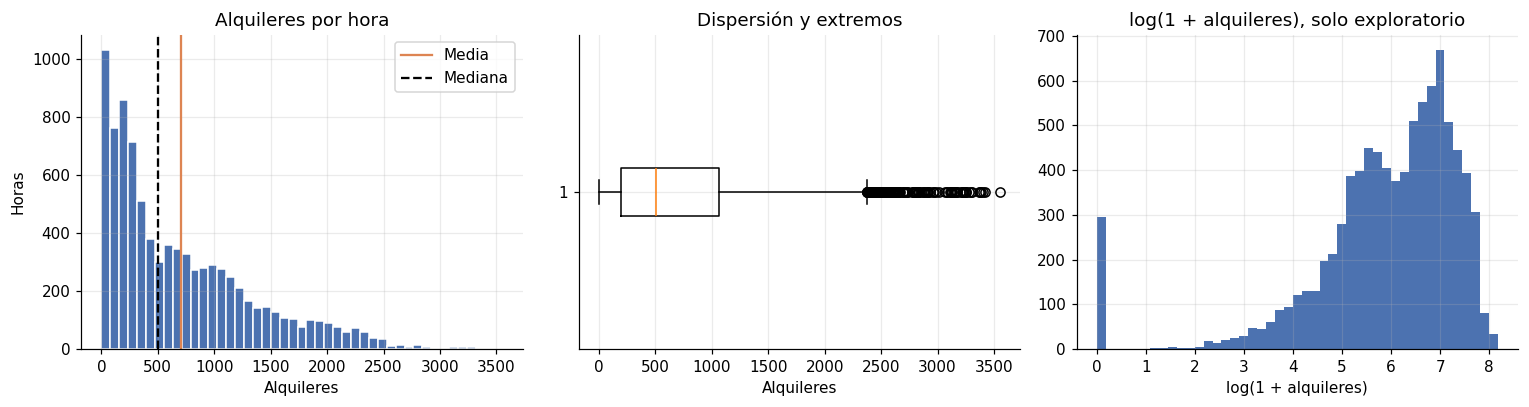

In [4]:
y = df[TARGET]
display(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame())
print(f"Total: {y.sum():,} | Ceros: {y.eq(0).sum():,} ({y.eq(0).mean():.2%}) | Asimetría: {y.skew():.3f}")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(y, bins=45, color=AZUL, edgecolor="white")
axes[0].axvline(y.mean(), color=NARANJA, label="Media")
axes[0].axvline(y.median(), color="black", ls="--", label="Mediana")
axes[0].legend(); axes[0].set_title("Alquileres por hora"); axes[0].set_ylabel("Horas")
axes[1].boxplot(y, vert=False); axes[1].set_title("Dispersión y extremos")
axes[2].hist(np.log1p(y), bins=45, color=AZUL)
axes[2].set_title("log(1 + alquileres), solo exploratorio")
for ax in axes: ax.set_xlabel("Alquileres" if ax != axes[2] else "log(1 + alquileres)")
fig.tight_layout(); plt.show()

## 3. Variables numéricas
### 3.1 Estadísticos, ceros y extremos
La regla IQR es una señal para investigar, no una orden de eliminar registros. Con lluvia muy esporádica, su IQR puede ser cero. Las temperaturas negativas son válidas.

In [5]:
NUM = [TARGET] + CLIMA
desc = df[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["asimetria"] = df[NUM].skew()
desc["ceros_pct"] = df[NUM].eq(0).mean() * 100
q1, q3 = df[NUM].quantile(.25), df[NUM].quantile(.75)
iqr = q3 - q1
desc["IQR"] = iqr
desc["fuera_IQR"] = ((df[NUM] < q1 - 1.5*iqr) | (df[NUM] > q3 + 1.5*iqr)).sum()
display(desc)

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetria,ceros_pct,IQR,fuera_IQR
alquileres,"8,760.000",704.602,644.997,0.000,0.000,191.000,504.500,"1,065.250","2,526.230","3,556.000",1.153,3.368,874.250,158
temperatura_c,"8,760.000",12.883,11.945,-17.800,-12.741,3.500,13.700,22.500,35.100,39.400,-0.198,0.240,19.000,0
humedad_pct,"8,760.000",58.226,20.362,0.000,17.000,42.000,57.000,74.000,97.000,98.000,0.060,0.194,32.000,0
viento_ms,"8,760.000",1.725,1.036,0.000,0.100,0.900,1.500,2.300,4.700,7.400,0.891,0.845,1.400,161
visibilidad_10m,"8,760.000","1,436.826",608.299,27.000,173.000,940.000,"1,698.000","2,000.000","2,000.000","2,000.000",-0.702,0.000,"1,060.000",0
rocio_c,"8,760.000",4.074,13.060,-30.600,-24.800,-4.700,5.100,14.800,24.700,27.200,-0.367,0.685,19.500,0
radiacion_mj_m2,"8,760.000",0.569,0.869,0.000,0.000,0.000,0.010,0.930,3.170,3.520,1.504,49.087,0.930,641
lluvia_mm,"8,760.000",0.149,1.128,0.000,0.000,0.000,0.000,0.000,4.000,35.000,14.533,93.973,0.000,528


### 3.2 Distribuciones y relación con la demanda

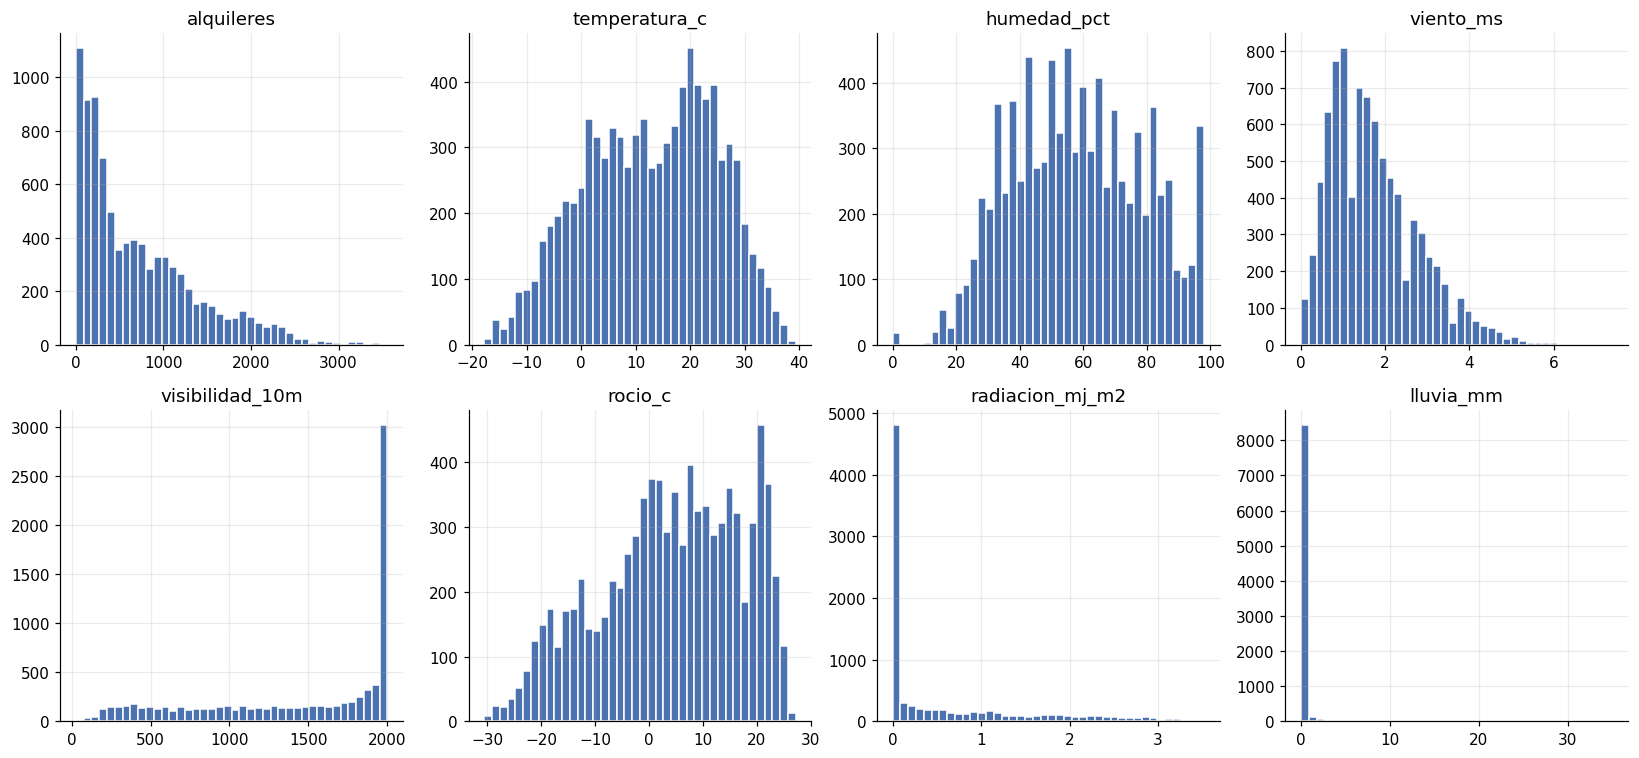

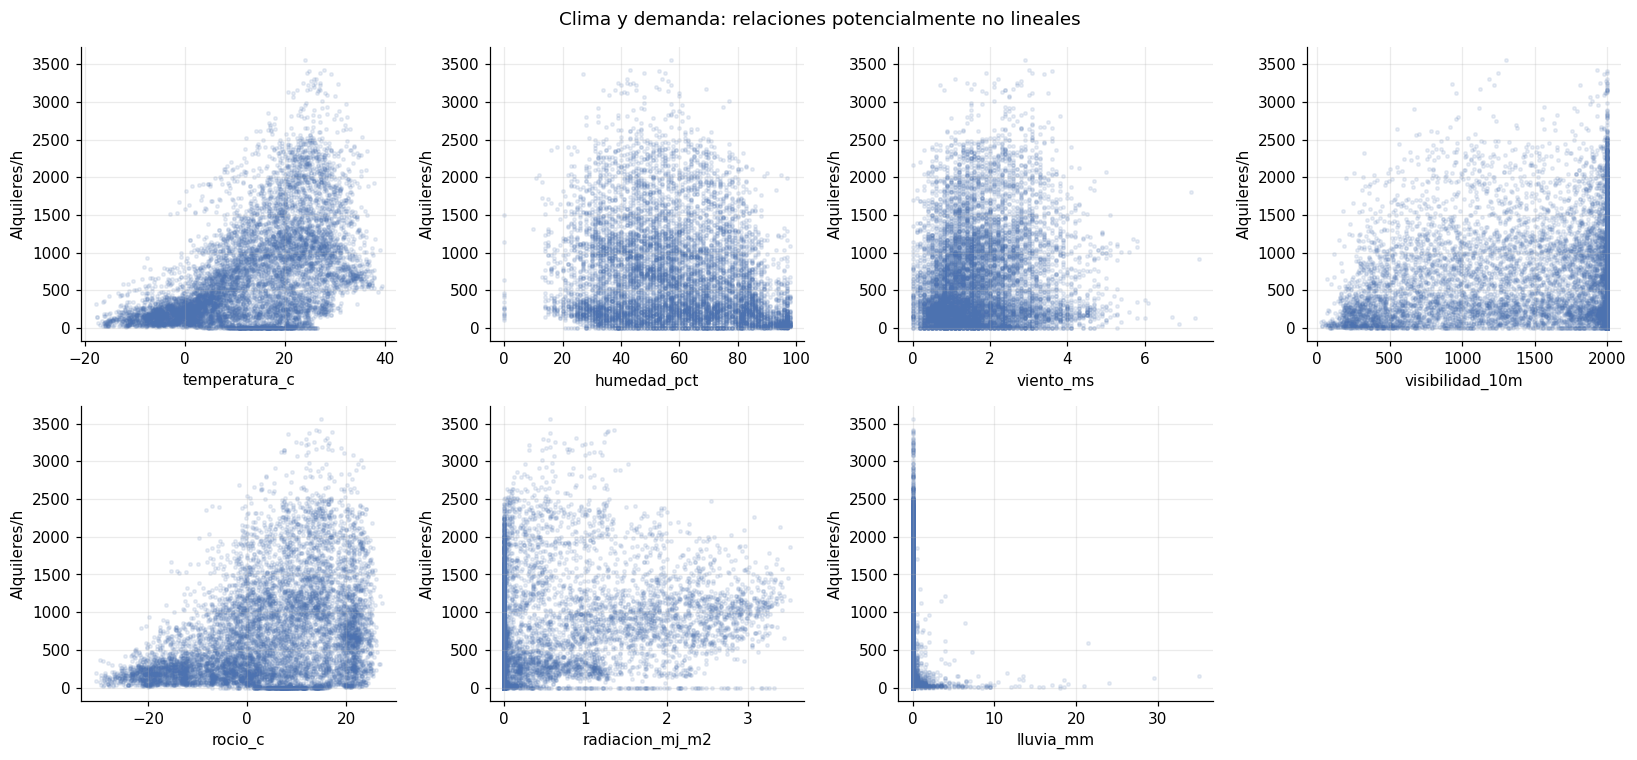

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, NUM):
    ax.hist(df[col], bins=40, color=AZUL, edgecolor="white"); ax.set_title(col)
fig.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, CLIMA):
    ax.scatter(df[col], y, s=5, alpha=.12, color=AZUL)
    ax.set_xlabel(col); ax.set_ylabel("Alquileres/h")
axes.flat[-1].set_visible(False)
fig.suptitle("Clima y demanda: relaciones potencialmente no lineales")
fig.tight_layout(); plt.show()

## 4. Calendario y demanda
Se deriva el calendario de la fecha. Fin de semana no equivale a festivo. Las estaciones son agrupaciones meteorológicas por mes, no una columna original.

In [7]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
df["mes"] = df.fecha.dt.month
df["periodo_mes"] = df.fecha.dt.to_period("M").astype(str)
df["dia_semana"] = df.fecha.dt.dayofweek
df["fin_semana"] = df.dia_semana.ge(5)
estaciones = {12: "Invierno", 1: "Invierno", 2: "Invierno", 3: "Primavera", 4: "Primavera", 5: "Primavera",
              6: "Verano", 7: "Verano", 8: "Verano", 9: "Otoño", 10: "Otoño", 11: "Otoño"}
df["estacion"] = df.mes.map(estaciones)
df["con_lluvia"] = df.lluvia_mm.gt(0)
def tabla_demanda(col):
    t = df.groupby(col, observed=True)[TARGET].agg(horas="size", media="mean", mediana="median", minimo="min", maximo="max")
    t["media_vs_global"] = t["media"] / y.mean()
    return t
for col in ["periodo_mes", "hora", "dia_semana", "estacion"]:
    print(col); display(tabla_demanda(col))

periodo_mes


,horas,media,mediana,minimo,maximo,media_vs_global
periodo_mes,,,,,,
2017-12,744,249.099,236.500,3,937,0.354
2018-01,744,201.621,181.500,18,702,0.286
2018-02,672,225.942,195.000,7,929,0.321
2018-03,744,511.551,460.000,2,2100,0.726
2018-04,720,728.093,655.000,0,2807,1.033
2018-05,744,950.387,874.000,0,3251,1.349
2018-06,720,"1,245.676","1,144.500",9,3556,1.768
2018-07,744,987.177,829.500,9,3196,1.401
2018-08,744,876.192,732.500,10,2836,1.244


hora


,horas,media,mediana,minimo,maximo,media_vs_global
hora,,,,,,
0,365,541.460,513.000,0,1394,0.768
1,365,426.184,401.000,0,1088,0.605
2,365,301.630,265.000,0,1254,0.428
3,365,203.332,176.000,0,644,0.289
4,365,132.592,119.000,0,421,0.188
5,365,139.082,129.000,0,383,0.197
6,365,287.564,232.000,0,807,0.408
7,365,606.005,426.000,0,1629,0.860
8,365,"1,015.701",728.000,0,2495,1.442


dia_semana


,horas,media,mediana,minimo,maximo,media_vs_global
dia_semana,,,,,,
0,1248,730.563,533.000,2,3380,1.037
1,1248,687.978,485.500,0,3556,0.976
2,1248,740.349,536.500,0,3384,1.051
3,1248,690.704,495.000,0,3418,0.980
4,1272,747.118,566.000,0,3365,1.060
5,1248,709.529,519.000,0,2497,1.007
6,1248,625.155,406.000,0,2514,0.887


estacion


,horas,media,mediana,minimo,maximo,media_vs_global
estacion,,,,,,
Invierno,2160,225.541,203.000,3,937,0.320
Otoño,2184,819.598,763.500,0,3298,1.163
Primavera,2208,730.031,583.000,0,3251,1.036
Verano,2208,"1,034.073",905.500,9,3556,1.468


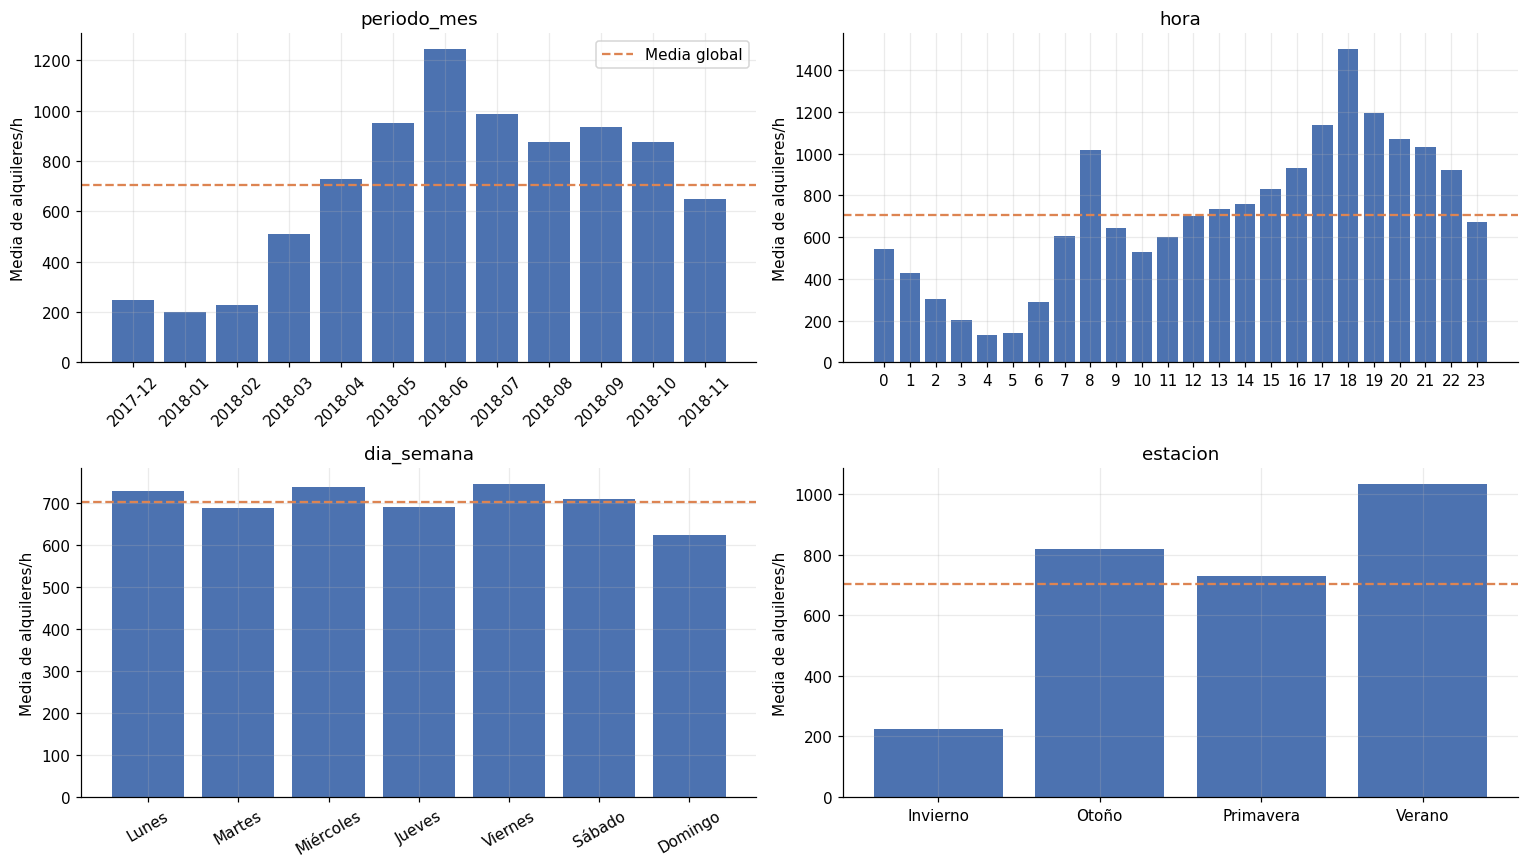

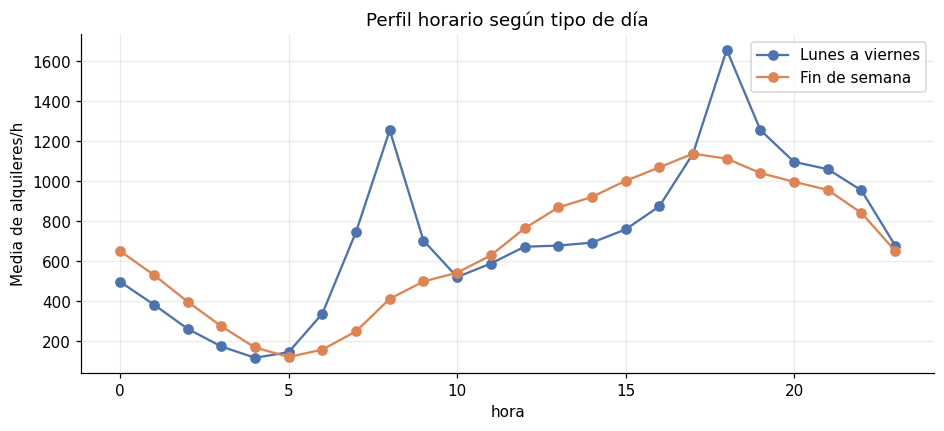

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.flat, ["periodo_mes", "hora", "dia_semana", "estacion"]):
    t = tabla_demanda(col)
    ax.bar(t.index.astype(str), t["media"], color=AZUL)
    ax.axhline(y.mean(), color=NARANJA, ls="--", label="Media global")
    ax.set_title(col); ax.set_ylabel("Media de alquileres/h")
    if col == "periodo_mes": ax.tick_params(axis="x", rotation=45)
    if col == "dia_semana": ax.set_xticks(range(7), DIAS, rotation=30)
axes[0, 0].legend(); fig.tight_layout(); plt.show()
perfil = df.groupby(["hora", "fin_semana"])[TARGET].mean().unstack()
perfil.columns = ["Lunes a viernes", "Fin de semana"]
perfil.plot(figsize=(10, 4), marker="o", color=[AZUL, NARANJA], ylabel="Media de alquileres/h",
            title="Perfil horario según tipo de día")
plt.show()

## 5. Asociación estadística con el objetivo
Pearson resume relaciones lineales y Spearman relaciones monótonas. Ninguna implica causalidad ni mide por sí sola toda la utilidad predictiva. No se aplican pruebas de independencia por fila: las horas están autocorrelacionadas.

In [9]:
ASOC = ["hora"] + CLIMA
asociacion = pd.DataFrame({m: df[ASOC + [TARGET]].corr(method=m)[TARGET].drop(TARGET)
                          for m in ["pearson", "spearman"]})
display(asociacion.sort_values("spearman", key=abs, ascending=False))
lluvia = tabla_demanda("con_lluvia")
display(lluvia)
print(f"Horas con lluvia: {df.con_lluvia.mean():.2%}")
print(f"Diferencia descriptiva respecto a horas secas: {1 - lluvia.loc[True, 'media']/lluvia.loc[False, 'media']:.2%}")
print("La diferencia mezcla horario, estación y otras condiciones; no es un efecto causal ajustado.")

,pearson,spearman
temperatura_c,0.539,0.565
hora,0.410,0.389
radiacion_mj_m2,0.262,0.382
rocio_c,0.380,0.374
lluvia_mm,-0.123,-0.282
humedad_pct,-0.200,-0.221
visibilidad_10m,0.199,0.176
viento_ms,0.121,0.148


,horas,media,mediana,minimo,maximo,media_vs_global
con_lluvia,,,,,,
False,8232,739.311,562.000,0,3556,1.049
True,528,163.456,67.000,0,2598,0.232


Horas con lluvia: 6.03%
Diferencia descriptiva respecto a horas secas: 77.89%
La diferencia mezcla horario, estación y otras condiciones; no es un efecto causal ajustado.


## 6. Análisis en profundidad
### 6.1 Segmentos meteorológicos
Se muestran tamaños de grupo para evitar interpretar segmentos pequeños como patrones sólidos.

,horas,media,mediana,minimo,maximo,media_vs_global
tramo_temperatura,,,,,,
≤0,1454,199.521,170.000,9,1671,0.283
0–10,2143,424.702,332.000,0,2202,0.603
10–20,2264,765.094,716.000,0,2857,1.086
20–30,2387,"1,119.993","1,058.000",0,3556,1.590
>30,512,"1,106.400",903.000,215,3238,1.570


,horas,media,mediana,minimo,maximo,media_vs_global
tramo_lluvia,,,,,,
Sin lluvia,8232,739.311,562.000,0,3556,1.049
"(0,1] mm",280,219.204,122.000,0,2598,0.311
"(1,5] mm",182,111.198,38.000,0,1208,0.158
>5 mm,66,71.061,24.000,0,858,0.101


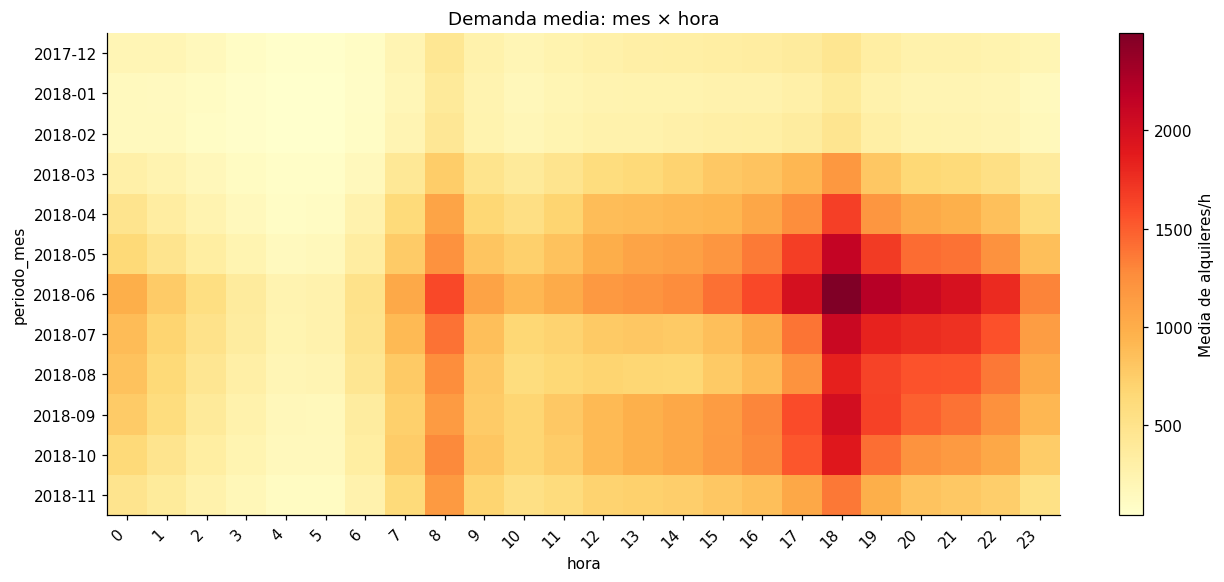

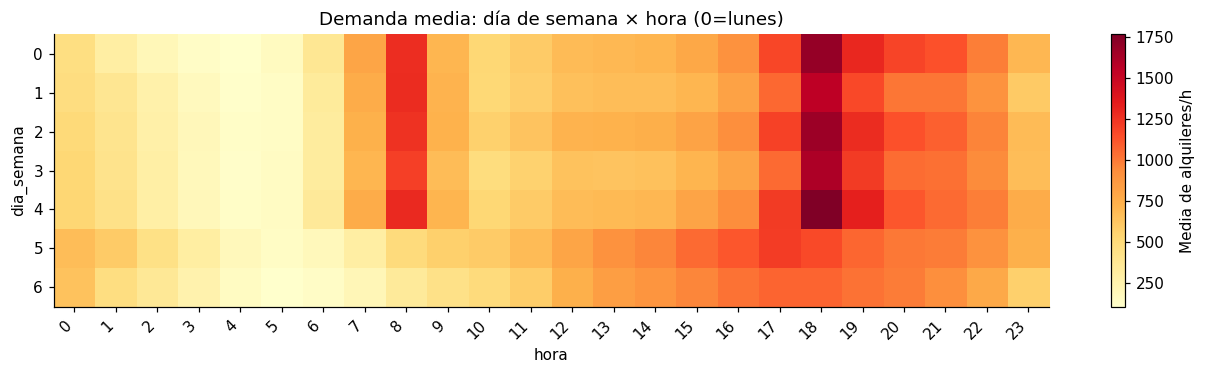

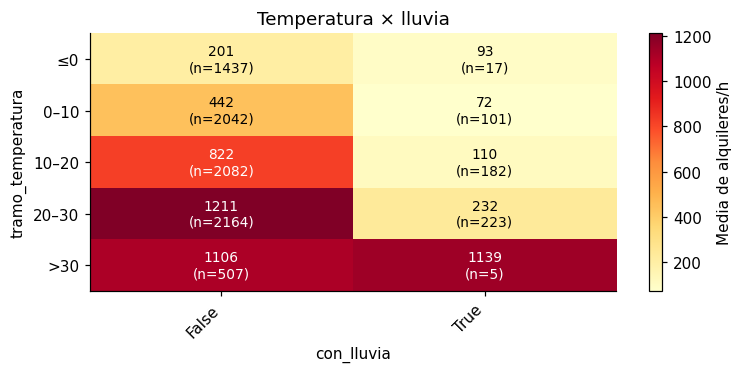

hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Tamaño de los grupos mes-hora,,,,,,,,,,,,,,,,,,,,,,,,
2017-12,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31
2018-01,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31
2018-02,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28
2018-03,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31
2018-04,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30
2018-05,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31
2018-06,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30
2018-07,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31
2018-08,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31,31


In [10]:
df["tramo_temperatura"] = pd.cut(df.temperatura_c, [-np.inf, 0, 10, 20, 30, np.inf],
                                    labels=["≤0", "0–10", "10–20", "20–30", ">30"])
df["tramo_lluvia"] = pd.cut(df.lluvia_mm, [-np.inf, 0, 1, 5, np.inf],
                               labels=["Sin lluvia", "(0,1] mm", "(1,5] mm", ">5 mm"])
for col in ["tramo_temperatura", "tramo_lluvia"]:
    display(tabla_demanda(col))

def mapa_demanda(filas, columnas, titulo, anotar=False):
    p = df.pivot_table(index=filas, columns=columnas, values=TARGET, aggfunc="mean", observed=True)
    n = df.pivot_table(index=filas, columns=columnas, values=TARGET, aggfunc="size", observed=True).reindex(index=p.index, columns=p.columns)
    fig, ax = plt.subplots(figsize=(max(7, .5*p.shape[1]), max(3.5, .45*p.shape[0])))
    im = ax.imshow(np.ma.masked_invalid(p.to_numpy()), cmap="YlOrRd", aspect="auto")
    ax.set_xticks(range(p.shape[1]), p.columns.astype(str), rotation=45, ha="right")
    ax.set_yticks(range(p.shape[0]), p.index.astype(str)); ax.grid(False)
    ax.set_xlabel(columnas); ax.set_ylabel(filas); ax.set_title(titulo)
    if anotar:
        for i in range(p.shape[0]):
            for j in range(p.shape[1]):
                if pd.notna(p.iloc[i,j]):
                    ax.text(j, i, f"{p.iloc[i,j]:.0f}\n(n={n.iloc[i,j]:.0f})", ha="center", va="center", fontsize=9,
                            color="white" if p.iloc[i,j] > p.max().max()*.65 else "black")
    fig.colorbar(im, ax=ax, label="Media de alquileres/h"); fig.tight_layout(); plt.show()
    return n

conteo_mes_hora = mapa_demanda("periodo_mes", "hora", "Demanda media: mes \u00d7 hora")
conteo_dia_hora = mapa_demanda("dia_semana", "hora", "Demanda media: día de semana \u00d7 hora (0=lunes)")
conteo_clima = mapa_demanda("tramo_temperatura", "con_lluvia", "Temperatura \u00d7 lluvia", anotar=True)
display(conteo_mes_hora.rename_axis("Tamaño de los grupos mes-hora"))

## 7. Análisis multivariante y dependencia temporal
### 7.1 Matriz de correlaciones
Temperatura y punto de rocío comparten información. En modelos lineales conviene revisar colinealidad; no se elimina ninguna variable aquí.

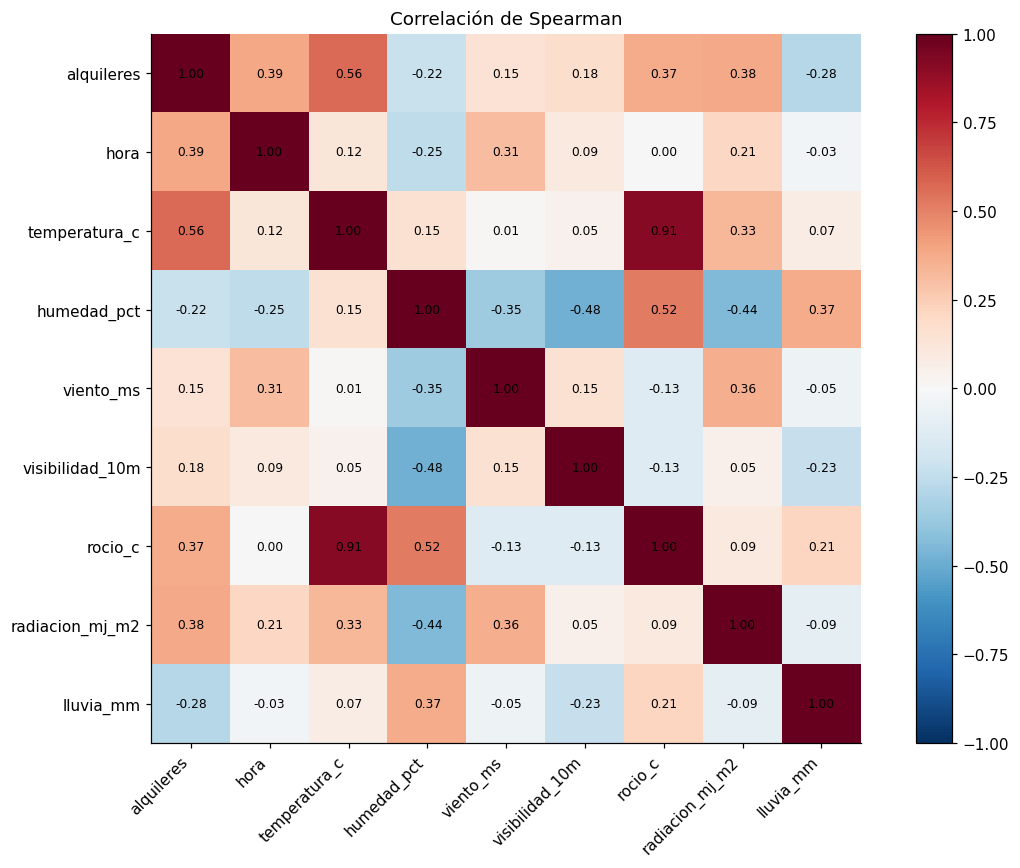

Pearson temperatura–rocío: 0.9127982187579924


In [11]:
cols = [TARGET, "hora"] + CLIMA
corr = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax); ax.set_title("Correlación de Spearman")
fig.tight_layout(); plt.show()
print("Pearson temperatura–rocío:", df.temperatura_c.corr(df.rocio_c))

### 7.2 Serie temporal, estacionalidad y rezagos
Se reindexa por hora para que un desplazamiento represente horas reales. La media móvil es retrospectiva; si se usara como predictor debe desplazarse para excluir el objetivo actual.

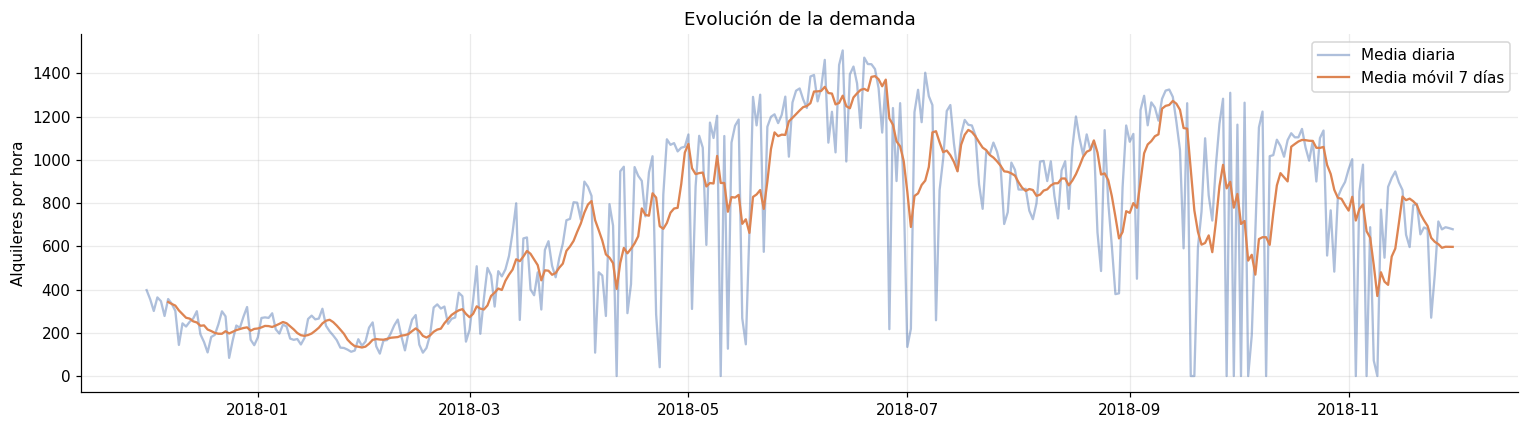

,autocorrelacion
rezago_horas,
1,0.903
2,0.764
24,0.682
48,0.655
168,0.661


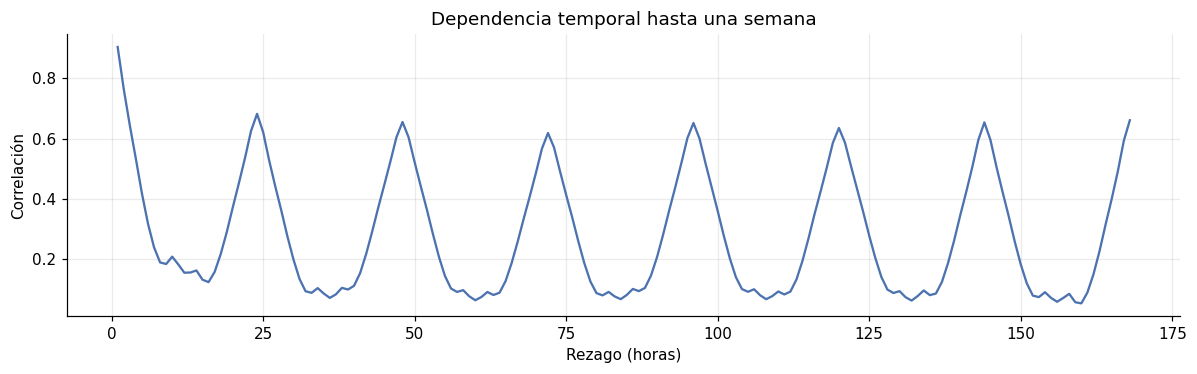

Solo hay un ciclo anual: no se puede comprobar estabilidad de la estacionalidad entre años.


In [12]:
serie = df.set_index("timestamp")[TARGET].reindex(esperadas)
diario = serie.resample("D").agg(["mean", "sum", "count"])
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(diario.index, diario["mean"], alpha=.45, color=AZUL, label="Media diaria")
ax.plot(diario.index, diario["mean"].rolling(7, min_periods=7).mean(), color=NARANJA, label="Media móvil 7 días")
ax.set_ylabel("Alquileres por hora"); ax.set_title("Evolución de la demanda"); ax.legend()
fig.tight_layout(); plt.show()
retardos = [1, 2, 24, 48, 168]
display(pd.Series({h: serie.autocorr(h) for h in retardos}, name="autocorrelacion").rename_axis("rezago_horas").to_frame())
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(range(1, 169), [serie.autocorr(h) for h in range(1, 169)], color=AZUL)
ax.set(xlabel="Rezago (horas)", ylabel="Correlación", title="Dependencia temporal hasta una semana")
fig.tight_layout(); plt.show()
print("Solo hay un ciclo anual: no se puede comprobar estabilidad de la estacionalidad entre años.")

## 8. Anomalías, relaciones estructurales y fuga de información
### 8.1 Ceros en el objetivo
**Decisión confirmada por el responsable del dataset:** los bloques de cero representan ausencia de registros. Se conservan las filas y sus valores originales, sin imputar ni eliminar esos conteos. No deben interpretarse como demanda real igual a cero. Las estadísticas anteriores describen el archivo tal como está, por lo que estos bloques reducen sus promedios. Para evaluar modelos habrá que excluir del cálculo del error las etiquetas ausentes, sin eliminar sus horas del calendario.

Días completos con cero alquileres: 12


,horas,ceros,total
fecha,,,
2018-04-11,24,24,0
2018-05-10,24,24,0
2018-09-18,24,24,0
2018-09-19,24,24,0
2018-09-28,24,24,0
2018-09-30,24,24,0
2018-10-02,24,24,0
2018-10-04,24,24,0
2018-10-09,24,24,0


,inicio,fin,horas
2,2018-04-11,2018-04-11 23:00:00,24
4,2018-05-10,2018-05-10 23:00:00,24
6,2018-09-18,2018-09-19 23:00:00,48
8,2018-09-28,2018-09-28 23:00:00,24
10,2018-09-30,2018-09-30 23:00:00,24
12,2018-10-02,2018-10-02 23:00:00,24
14,2018-10-04,2018-10-04 23:00:00,24
16,2018-10-06,2018-10-06 06:00:00,7
18,2018-10-09,2018-10-09 23:00:00,24
20,2018-11-03,2018-11-03 23:00:00,24


,horas_cero,proporcion_cero
periodo_mes,,
2017-12,0,0.000
2018-01,0,0.000
2018-02,0,0.000
2018-03,0,0.000
2018-04,24,0.033
2018-05,24,0.032
2018-06,0,0.000
2018-07,0,0.000
2018-08,0,0.000


Con lluvia,False,True
Cero alquileres,,
False,7949,516
True,283,12


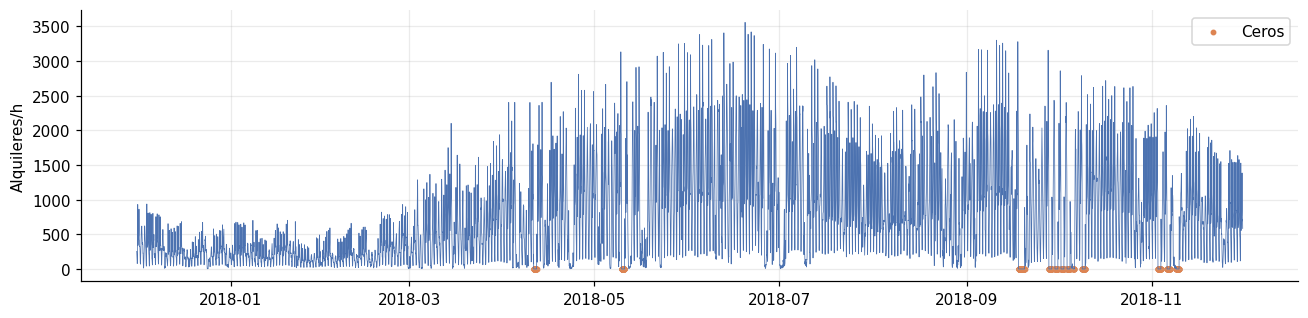

In [13]:
df["objetivo_cero"] = df[TARGET].eq(0)
ceros_dia = df.groupby("fecha").agg(horas=(TARGET, "size"), ceros=("objetivo_cero", "sum"), total=(TARGET, "sum"))
dias_cero = ceros_dia.query("horas == 24 and ceros == 24")
print("Días completos con cero alquileres:", len(dias_cero)); display(dias_cero)
# Los bloques también se separan si hubiera saltos temporales.
nuevo_bloque = df.objetivo_cero.ne(df.objetivo_cero.shift()) | df.timestamp.diff().ne(pd.Timedelta(hours=1))
bloques_cero = df.loc[df.objetivo_cero].groupby(nuevo_bloque.cumsum()).agg(
    inicio=("timestamp", "min"), fin=("timestamp", "max"), horas=(TARGET, "size"))
display(bloques_cero)
ceros_mes = df.groupby("periodo_mes").objetivo_cero.agg(["sum", "mean"])
ceros_mes.columns = ["horas_cero", "proporcion_cero"]; display(ceros_mes)
display(pd.crosstab(df.objetivo_cero, df.con_lluvia, rownames=["Cero alquileres"], colnames=["Con lluvia"]))
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(serie, color=AZUL, lw=.5)
ax.scatter(df.loc[df.objetivo_cero, "timestamp"], df.loc[df.objetivo_cero, TARGET], color=NARANJA, s=8, label="Ceros")
ax.set_ylabel("Alquileres/h"); ax.legend(); fig.tight_layout(); plt.show()

### 8.2 Humedad, límites físicos y valores sospechosos
Se tratarán los 0 % de humedad como valores a imputar por decisión del proyecto. Se conservarán el valor original y un indicador de imputación. Más adelante se construye una copia corregida para el EDA. La visibilidad de 2.000 podría ser un techo de reporte (20 km); no se modifica.

In [14]:
reglas = pd.Series({
    "alquileres negativos": (y < 0).sum(),
    "alquileres no enteros": y.mod(1).ne(0).sum(),
    "humedad fuera de [0,100]": (~df.humedad_pct.between(0,100)).sum(),
    "humedad igual a cero (sospechosa)": df.humedad_pct.eq(0).sum(),
    "viento negativo": df.viento_ms.lt(0).sum(),
    "lluvia negativa": df.lluvia_mm.lt(0).sum(),
    "radiacion negativa": df.radiacion_mj_m2.lt(0).sum(),
    "visibilidad negativa": df.visibilidad_10m.lt(0).sum(),
    "rocio superior a temperatura": df.rocio_c.gt(df.temperatura_c).sum(),
    "visibilidad igual a 2000": df.visibilidad_10m.eq(2000).sum(),
}, name="registros")
display(reglas.to_frame())
display(df.loc[df.humedad_pct.eq(0), ["timestamp", TARGET] + CLIMA])
print(f"Visibilidad = 2000: {df.visibilidad_10m.eq(2000).mean():.2%}")
print("Mayores conteos: revisar contexto, no eliminar automáticamente")
display(df.nlargest(10, TARGET)[["timestamp", TARGET] + CLIMA])

,registros
alquileres negativos,0
alquileres no enteros,0
"humedad fuera de [0,100]",0
humedad igual a cero (sospechosa),17
viento negativo,0
lluvia negativa,0
radiacion negativa,0
visibilidad negativa,0
rocio superior a temperatura,0
visibilidad igual a 2000,2245


,timestamp,alquileres,temperatura_c,humedad_pct,viento_ms,visibilidad_10m,rocio_c,radiacion_mj_m2,lluvia_mm
4063,2018-05-19 07:00:00,436,11.400,0,1.400,2000,4.500,0.460,0.000
4106,2018-05-21 02:00:00,262,13.900,0,0.900,2000,-2.100,0.000,0.000
4107,2018-05-21 03:00:00,165,13.000,0,0.800,2000,-2.500,0.000,0.000
4108,2018-05-21 04:00:00,113,12.400,0,0.800,2000,-3.400,0.000,0.000
4109,2018-05-21 05:00:00,200,11.900,0,1.300,2000,-2.700,0.000,0.000
4110,2018-05-21 06:00:00,467,11.400,0,0.900,2000,-2.000,0.030,0.000
4111,2018-05-21 07:00:00,1135,12.300,0,0.900,1989,-2.700,0.480,0.000
4131,2018-05-22 03:00:00,406,15.500,0,0.700,1420,10.400,0.000,0.000
4132,2018-05-22 04:00:00,248,15.600,0,0.500,1502,10.500,0.000,0.000
4133,2018-05-22 05:00:00,182,15.700,0,0.600,1610,10.600,0.000,0.000


Visibilidad = 2000: 25.63%
Mayores conteos: revisar contexto, no eliminar automáticamente


,timestamp,alquileres,temperatura_c,humedad_pct,viento_ms,visibilidad_10m,rocio_c,radiacion_mj_m2,lluvia_mm
4818,2018-06-19 18:00:00,3556,24.100,57,2.900,1301,15.000,0.560,0.000
4866,2018-06-21 18:00:00,3418,27.800,43,3.000,1933,14.000,1.350,0.000
4650,2018-06-12 18:00:00,3404,24.900,53,3.600,2000,14.600,1.280,0.000
4842,2018-06-20 18:00:00,3384,27.000,55,3.100,1246,17.100,1.260,0.000
4458,2018-06-04 18:00:00,3380,24.400,48,1.900,1998,12.600,0.560,0.000
4890,2018-06-22 18:00:00,3365,29.300,27,3.400,1977,8.300,1.240,0.000
4554,2018-06-08 18:00:00,3309,26.200,54,2.200,1183,16.100,0.880,0.000
6810,2018-09-10 18:00:00,3298,25.900,42,1.100,2000,11.900,0.480,0.000
6978,2018-09-17 18:00:00,3277,25.300,56,2.800,1992,15.800,0.540,0.000
6858,2018-09-12 18:00:00,3256,27.000,44,1.400,2000,13.600,0.620,0.000


### 8.3 Sensibilidad descriptiva a registros sospechosos
Excluir ceros aquí es solo una comparación exploratoria, no una regla de limpieza. También cambia qué días quedan representados. No se usa `objetivo_cero` como predictor: está calculado a partir de la respuesta.

In [15]:
escenarios = {"Original": df, "Sin objetivo cero (solo sensibilidad)": df.loc[~df.objetivo_cero],
              "Sin humedad cero (solo sensibilidad)": df.loc[df.humedad_pct.ne(0)]}
resumen = []
for nombre, datos in escenarios.items():
    resumen.append({"escenario": nombre, "horas": len(datos), "media": datos[TARGET].mean(),
                    "mediana": datos[TARGET].median(), "corr_temperatura": datos[TARGET].corr(datos.temperatura_c),
                    "corr_humedad": datos[TARGET].corr(datos.humedad_pct)})
display(pd.DataFrame(resumen).set_index("escenario"))

,horas,media,mediana,corr_temperatura,corr_humedad
escenario,,,,,
Original,8760,704.602,504.500,0.539,-0.200
Sin objetivo cero (solo sensibilidad),8465,729.157,542.000,0.563,-0.202
Sin humedad cero (solo sensibilidad),8743,705.179,506.000,0.539,-0.204


### 8.3.1 Copia preparada: nombres, timestamp e imputación de humedad
Se promedian **las dos medias mensuales**: (media del mes anterior + media del mes posterior) / 2, excluyendo humedad cero o nula. No se agrupan meses de años distintos. Si falta cualquiera de los dos meses, el valor queda pendiente, sin aplicar una alternativa silenciosa.

Esta copia se prepara después del análisis del archivo original: sus tablas y gráficos anteriores no se recalculan con datos imputados. El mes posterior implica información futura; esta es una corrección retrospectiva para el EDA, no un preprocesamiento aprobado para pronosticar.

In [16]:
df_preparado = df.copy()
df_preparado["alquileres_registro_ausente"] = df_preparado["objetivo_cero"]
df_preparado["humedad_original_pct"] = df_preparado["humedad_pct"]
df_preparado["humedad_a_imputar"] = df_preparado["humedad_pct"].eq(0) | df_preparado["humedad_pct"].isna()
mes_calendario = df_preparado["timestamp"].dt.to_period("M")
humedad_valida = df_preparado["humedad_pct"].mask(df_preparado["humedad_a_imputar"])
media_mes = humedad_valida.groupby(mes_calendario).mean()
media_anterior = (mes_calendario - 1).map(media_mes)
media_posterior = (mes_calendario + 1).map(media_mes)
relleno = (media_anterior + media_posterior) / 2
mascara = df_preparado["humedad_a_imputar"]
df_preparado["humedad_pct"] = humedad_valida.where(~mascara, relleno)
df_preparado["humedad_imputada"] = mascara & df_preparado["humedad_pct"].notna()
auditoria_humedad = pd.DataFrame({
    "timestamp": df_preparado["timestamp"], "original": df_preparado["humedad_original_pct"],
    "media_mes_anterior": media_anterior, "media_mes_posterior": media_posterior,
    "humedad_resultante": df_preparado["humedad_pct"],
}).loc[mascara]
display(auditoria_humedad)
print("Imputados:", df_preparado.humedad_imputada.sum())
print("Pendientes por falta de meses vecinos:", df_preparado.humedad_pct.isna().sum())
# Vista analítica del objetivo: ausente no equivale a demanda cero.
# No modifica alquileres ni elimina filas; no se usa para imputar etiquetas.
df_preparado["alquileres_observados"] = df_preparado[TARGET].mask(
    df_preparado["alquileres_registro_ausente"])
assert df_preparado[TARGET].equals(df[TARGET])
assert df_preparado.timestamp.is_unique
assert df_preparado.timestamp.notna().all()
assert df_preparado.humedad_pct.dropna().between(0, 100).all()
assert df_preparado.loc[~mascara, "humedad_pct"].equals(humedad_valida.loc[~mascara])
print("Filas conservadas:", len(df_preparado))
print("Objetivos ausentes señalados:", df_preparado.alquileres_registro_ausente.sum())
display(df_preparado[["timestamp", TARGET, "alquileres_registro_ausente",
                      "alquileres_observados", "humedad_original_pct",
                      "humedad_pct", "humedad_imputada"]].loc[mascara].head())
# No se exporta ni se sobrescribe data/SeoulBikeData.csv.

,timestamp,original,media_mes_anterior,media_mes_posterior,humedad_resultante
4063,2018-05-19 07:00:00,0,54.611,62.618,58.615
4106,2018-05-21 02:00:00,0,54.611,62.618,58.615
4107,2018-05-21 03:00:00,0,54.611,62.618,58.615
4108,2018-05-21 04:00:00,0,54.611,62.618,58.615
4109,2018-05-21 05:00:00,0,54.611,62.618,58.615
4110,2018-05-21 06:00:00,0,54.611,62.618,58.615
4111,2018-05-21 07:00:00,0,54.611,62.618,58.615
4131,2018-05-22 03:00:00,0,54.611,62.618,58.615
4132,2018-05-22 04:00:00,0,54.611,62.618,58.615
4133,2018-05-22 05:00:00,0,54.611,62.618,58.615


Imputados: 17
Pendientes por falta de meses vecinos: 0
Filas conservadas: 8760
Objetivos ausentes señalados: 295


,timestamp,alquileres,alquileres_registro_ausente,alquileres_observados,humedad_original_pct,humedad_pct,humedad_imputada
4063,2018-05-19 07:00:00,436,False,436.000,0,58.615,True
4106,2018-05-21 02:00:00,262,False,262.000,0,58.615,True
4107,2018-05-21 03:00:00,165,False,165.000,0,58.615,True
4108,2018-05-21 04:00:00,113,False,113.000,0,58.615,True
4109,2018-05-21 05:00:00,200,False,200.000,0,58.615,True


### 8.4 Pronóstico de un día completo y disponibilidad de información
**Horizonte acordado:** generar antes del inicio del día siguiente sus 24 predicciones horarias. Es la interpretación adoptada de “día completo”; el total diario se obtiene sumando las 24 predicciones.
- Usar únicamente datos disponibles al emitir el pronóstico: calendario futuro y, si se dispone de ellos, pronósticos meteorológicos. El clima realmente observado durante el día futuro sirve para describir el pasado, pero no es una entrada disponible de antemano.
- Los rezagos de una hora no estarán disponibles para todas las horas futuras. Los ejemplos siguientes son exploratorios y deben adaptarse a un origen de pronóstico fijo. Un rezago de 24 horas exige que el dato de ayer ya haya llegado al sistema.
- No usar conteos ausentes como ceros reales para construir rezagos, medias o etiquetas de entrenamiento. Se conservan en la tabla original y se señalan en la copia analítica.
- Imputación, escalado y selección de variables deben ajustarse usando exclusivamente el entrenamiento de cada ventana. La imputación con el mes posterior se reserva a reconstrucción retrospectiva, no a la evaluación predictiva.
- La comparación prevista incluye regresión lineal, Random Forest y Gradient Boosting, con MAE/RMSE y referencias del día/semana anterior cuando sus datos estén disponibles.
- El CSV no identifica festivos ni contiene pronósticos meteorológicos históricos.

In [17]:
# Ejemplos de ingeniería, sin entrenar ni escribir una versión limpia del CSV.
features_temporales = pd.DataFrame(index=serie.index)
for h in [1, 24, 168]:
    features_temporales[f"lag_{h}h"] = serie.shift(h)
features_temporales["media_24h_pasadas"] = serie.shift(1).rolling(24, min_periods=24).mean()
features_temporales["hora_sin"] = np.sin(2*np.pi*features_temporales.index.hour/24)
features_temporales["hora_cos"] = np.cos(2*np.pi*features_temporales.index.hour/24)
display(features_temporales.iloc[168:173])
# Ejemplo de partición cronológica (no es una evaluación del rendimiento).
corte1, corte2 = int(len(df)*.70), int(len(df)*.85)
particiones = {"Entrenamiento": df.iloc[:corte1], "Validación": df.iloc[corte1:corte2], "Prueba": df.iloc[corte2:]}
display(pd.DataFrame([{"particion": k, "desde": v.timestamp.min(), "hasta": v.timestamp.max(),
                       "horas": len(v), "media_objetivo": v[TARGET].mean()} for k,v in particiones.items()]))
print("El 70/15/15 es ilustrativo: cubre estaciones distintas y requiere validación temporal adicional.")

,lag_1h,lag_24h,lag_168h,media_24h_pasadas,hora_sin,hora_cos
2017-12-08 00:00:00,259.000,198.000,254.000,356.208,0.000,1.000
2017-12-08 01:00:00,233.000,218.000,204.000,357.667,0.259,0.966
2017-12-08 02:00:00,230.000,149.000,173.000,358.167,0.500,0.866
2017-12-08 03:00:00,131.000,102.000,107.000,357.417,0.707,0.707
2017-12-08 04:00:00,99.000,62.000,78.000,357.292,0.866,0.500


,particion,desde,hasta,horas,media_objetivo
0,Entrenamiento,2017-12-01 00:00:00,2018-08-13 11:00:00,6132,649.903
1,Validación,2018-08-13 12:00:00,2018-10-07 05:00:00,1314,877.216
2,Prueba,2018-10-07 06:00:00,2018-11-30 23:00:00,1314,787.249


El 70/15/15 es ilustrativo: cubre estaciones distintas y requiere validación temporal adicional.


## 9. Información mutua exploratoria
Se adapta la sección del ejemplo a **regresión** (`mutual_info_regression`). Detecta dependencias no lineales por variable; no es importancia de un modelo ni demuestra causalidad. Se calcula solo sobre la partición inicial de entrenamiento del ejemplo para no usar el bloque final como criterio de selección. El resultado depende del periodo, de la discretización y de la autocorrelación; no se descartan variables automáticamente. Temperatura y mes pueden compartir señal estacional.

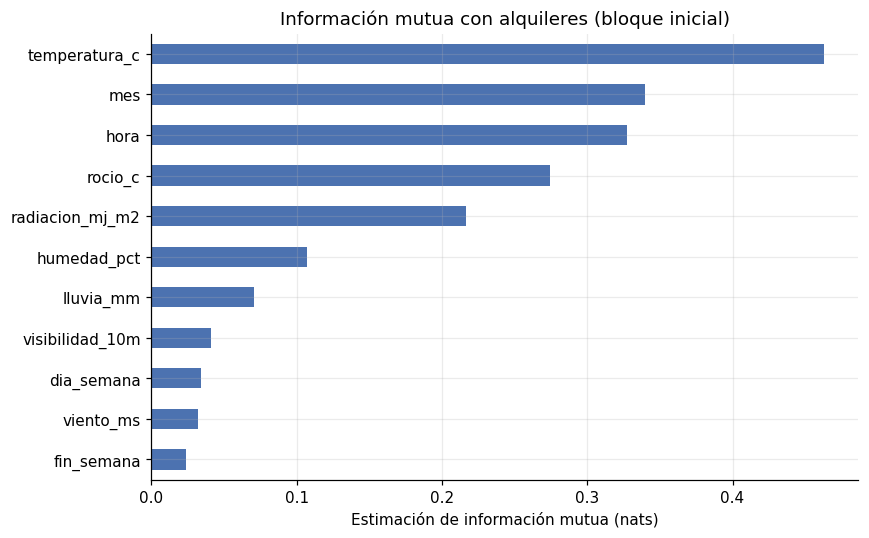

,informacion_mutua
temperatura_c,0.463
mes,0.340
hora,0.327
rocio_c,0.274
radiacion_mj_m2,0.217
humedad_pct,0.107
lluvia_mm,0.070
visibilidad_10m,0.041
dia_semana,0.034
viento_ms,0.032


In [18]:
FEATURES = CLIMA + ["hora", "mes", "dia_semana", "fin_semana"]
train_eda = particiones["Entrenamiento"]
X = train_eda[FEATURES].astype(float)
discretas = [c in ["hora", "mes", "dia_semana", "fin_semana"] for c in FEATURES]
mi = mutual_info_regression(X, train_eda[TARGET], discrete_features=discretas, random_state=42)
info_mutua = pd.Series(mi, index=FEATURES, name="informacion_mutua").sort_values()
ax = info_mutua.plot.barh(figsize=(8, 5), color=AZUL, title="Información mutua con alquileres (bloque inicial)")
ax.set_xlabel("Estimación de información mutua (nats)"); plt.tight_layout(); plt.show()
display(info_mutua.sort_values(ascending=False).to_frame())

## 10. Hallazgos y próximos pasos
Las cifras del resumen se calculan desde las celdas anteriores para mantenerlo verificable.

In [19]:
mensual = tabla_demanda("periodo_mes")
horaria = tabla_demanda("hora")
print(f"1. Estructura: {len(df):,} horas, {original.shape[1]} columnas originales; {len(faltantes)} horas faltantes.")
print(f"2. Demanda: media {y.mean():.1f}, mediana {y.median():.1f}, máximo {y.max():,}; total {y.sum():,}.")
print(f"3. Ceros: {y.eq(0).sum()} horas ({y.eq(0).mean():.2%}); {len(dias_cero)} días completos.")
print(f"4. Humedad cero: {df.humedad_pct.eq(0).sum()} registros; visibilidad en 2000: {df.visibilidad_10m.eq(2000).mean():.2%}.")
print(f"5. Máximo horario medio: {horaria['media'].idxmax():02d}:00 ({horaria['media'].max():.1f}); mínimo: {horaria['media'].idxmin():02d}:00 ({horaria['media'].min():.1f}).")
print(f"6. Mes con mayor media: {mensual['media'].idxmax()} ({mensual['media'].max():.1f}); menor: {mensual['media'].idxmin()} ({mensual['media'].min():.1f}).")
print(f"7. Con lluvia: {lluvia.loc[True, 'media']:.1f} alquileres/h; sin lluvia: {lluvia.loc[False, 'media']:.1f}.")
print(f"8. Dependencia: correlación a 1 h = {serie.autocorr(1):.3f}, a 24 h = {serie.autocorr(24):.3f}.")

1. Estructura: 8,760 horas, 10 columnas originales; 0 horas faltantes.
2. Demanda: media 704.6, mediana 504.5, máximo 3,556; total 6,172,314.
3. Ceros: 295 horas (3.37%); 12 días completos.
4. Humedad cero: 17 registros; visibilidad en 2000: 25.63%.
5. Máximo horario medio: 18:00 (1502.9); mínimo: 04:00 (132.6).
6. Mes con mayor media: 2018-06 (1245.7); menor: 2018-01 (201.6).
7. Con lluvia: 163.5 alquileres/h; sin lluvia: 739.3.
8. Dependencia: correlación a 1 h = 0.903, a 24 h = 0.682.


**Decisiones antes de modelar**
1. Los bloques de cero son ausencias de registros, según la confirmación recibida. Se conservan sin reemplazar ni eliminar; no representan demanda observada. Para entrenamiento y métricas se necesita una máscara de etiquetas disponibles.
2. Se incorpora una imputación retrospectiva de humedad: promedio de las medias válidas del mes calendario anterior y posterior, con igual peso por mes. Se conservan el dato original y el indicador. Esta regla usa futuro y no puede trasladarse a una evaluación real de pronósticos.
3. Nombres normalizados, unidades y timestamp explícito ya están implementados. La copia preparada y sus comprobaciones aparecen en la sección 8; el CSV original se conserva.
4. Se pronosticará el día siguiente completo: 24 valores horarios, cuyo total puede sumarse.
5. Se compararán regresión lineal, Random Forest y Gradient Boosting contra referencias temporales. Se usarán MAE y RMSE sobre registros con objetivo realmente observado.
6. La validación simulará varios días futuros en orden cronológico, usando solo información disponible en cada origen.

**Qué significa validar en orden temporal**

Imagina que hoy es 30 de junio: para predecir el 1 de julio solo puedes aprender de datos disponibles hasta el 30 de junio. Después avanzas: con lo disponible hasta el 1 de julio predices el 2. Repetirlo en varios días permite comprobar si el modelo funciona en distintos momentos, en lugar de depender de un único día favorable. Más abajo se muestran fechas de ejemplo; no se entrenan modelos.

“Sin ajustar transformaciones con el futuro” significa que ni siquiera una media para rellenar datos puede mirar lo que todavía no habría ocurrido. Por ejemplo, completar mayo usando junio es válido para reconstruir una tabla después de terminar junio, pero no para simular una predicción que se emitió en mayo. En cada evaluación deberá emplearse otra regla basada solo en el pasado.

También conviene reservar el último periodo como prueba final, sin usarlo para elegir el modelo. Como el archivo solo cubre un año, todavía no sabemos si un patrón aprendido en un verano se repetirá el verano siguiente.

**Hasta dónde llegan estas conclusiones**

Este notebook describe lo que aparece en el archivo y detecta relaciones; todavía no demuestra que un modelo prediga bien ni que una variable cause cambios en otra.

Por ejemplo: las horas lluviosas tienen menos alquileres en promedio. Eso no significa que, al llover mañana, la demanda vaya a bajar exactamente ese porcentaje: también influyen la hora, el mes y otras condiciones. Para saber cuánto acertamos mañana debemos entrenar un modelo y compararlo con registros futuros realmente observados.

Se incorporó tu confirmación de que los bloques de cero son registros ausentes. No se consultó una fuente externa de festivos o sensores para verificar las demás hipótesis. La humedad se corrigió únicamente en una copia en memoria: el CSV no se sobrescribió. No se ha entrenado ni comparado el rendimiento de los tres modelos.

### Ejemplo de ventanas para evaluar el día siguiente
Las ventanas son ejemplos, no resultados de rendimiento. En cada una se ajustarán modelo y preprocesamiento con el pasado. El bloque final de noviembre puede reservarse para la prueba final; las fechas de validación siguientes no lo utilizan.

In [20]:
ventanas = []
for fecha_objetivo in pd.to_datetime(["2018-07-01", "2018-08-01", "2018-09-01", "2018-10-01"]):
    pasado = df_preparado.loc[df_preparado.timestamp < fecha_objetivo]
    futuro = df_preparado.loc[
        df_preparado.timestamp.ge(fecha_objetivo)
        & df_preparado.timestamp.lt(fecha_objetivo + pd.Timedelta(days=1))]
    ventanas.append({
        "entrenamiento_desde": pasado.timestamp.min(),
        "ultimo_dato_entrenamiento": pasado.timestamp.max(),
        "dia_a_predecir": fecha_objetivo,
        "horas_a_predecir": len(futuro),
        "etiquetas_observadas_para_evaluar": futuro.alquileres_observados.notna().sum(),
    })
display(pd.DataFrame(ventanas))
print("No se han entrenado modelos. Los ceros por ausencia se conservan, pero no son etiquetas válidas.")


,entrenamiento_desde,ultimo_dato_entrenamiento,dia_a_predecir,horas_a_predecir,etiquetas_observadas_para_evaluar
0,2017-12-01,2018-06-30 23:00:00,2018-07-01,24,24
1,2017-12-01,2018-07-31 23:00:00,2018-08-01,24,24
2,2017-12-01,2018-08-31 23:00:00,2018-09-01,24,24
3,2017-12-01,2018-09-30 23:00:00,2018-10-01,24,24


No se han entrenado modelos. Los ceros por ausencia se conservan, pero no son etiquetas válidas.
